# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** Нугаева Камилла, J3312, 434674. Выбран вариант NLP.

- Устройство: CPU; точная платформа, версии библиотек и время выводятся ниже и сохраняются в `artifacts/environment.json`. Код автоматически использует CUDA / MPS, если они доступны.
- Модель: [Google BERT-Mini, L4/H256/A4](https://huggingface.co/google/bert_uncased_L-4_H-256_A-4), Apache-2.0; это базовый предобученный энкодер, без обучения на NER. Ревизия зафиксирована полным SHA.
- Данные: [Few-NERD, supervised](https://huggingface.co/datasets/DFKI-SLT/few-nerd), CC BY-SA 4.0, английская Wikipedia, ручная разметка. Используются 8 крупных типов, фиксированное подмножество 8000/1500/1500 предложений с удалением точных повторов между сплитами. Это учебный бюджет, а не результат на полном официальном бенчмарке.
- Бонусы: 6.2 (BERT-Tiny), 6.3 (сдвиг), 6.4 (INT8-квантизация на CPU), 6.5 (порог уверенности). 6.1 не выбран: новая ручная разметка не выполнялась.
- Источники: исходный шаблон ДЗ2; [Hugging Face token classification](https://huggingface.co/docs/transformers/tasks/token_classification), [Trainer](https://huggingface.co/docs/transformers/main_classes/trainer), [Ding et al., Few-NERD, ACL 2021](https://aclanthology.org/2021.acl-long.248/), [BERT Miniatures](https://huggingface.co/google/bert_uncased_L-4_H-256_A-4), [PyTorch quantize_dynamic](https://docs.pytorch.org/docs/stable/generated/torch.ao.quantization.quantize_dynamic.html). Для подготовки кода и текста использован ChatGPT/Codex; числа получены выполнением ноутбука.
- Основные задачи 1.1–5.3 реализованы; статус выполнения подтверждается outputs, без подстановки заранее придуманных метрик. Датасет и веса не входят в сдачу. Все численные ответы ниже формируются из текущего запуска.


In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.15.0+cpu, transformers 5.22.1, datasets 5.1.0
CUDA available: False


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cpu cpu


In [4]:
import gc
import hashlib
import io
import platform
import sys
from IPython.display import Markdown, display

# Небольшие матрицы на CPU не выигрывают от большого числа потоков.
CPU_THREADS = min(4, os.cpu_count() or 1)
torch.set_num_threads(CPU_THREADS)
print('CPU threads:', CPU_THREADS, '| platform:', platform.platform())


CPU threads: 4 | platform: Linux-6.18.57-x86_64-with-glibc2.41


In [5]:
FAST_MODE = False  # финальная сдача; для проверки переключить на True
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 512 if FAST_MODE else None
N_EVAL = 128 if FAST_MODE else None
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}


---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [6]:
MODEL_ID = 'google/bert_uncased_L-4_H-256_A-4'
REVISION = '387825ce42dbb39b87911cdf8e383ee3b25184f8'
TOKENIZER_KWARGS = {'use_fast': True, 'do_lower_case': True}


In [7]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    google/bert_uncased_L-4_H-256_A-4
revision: 387825ce42dbb39b87911cdf8e383ee3b25184f8
license:  apache-2.0
language: None
updated:  2021-05-19 17:30:27+00:00
weights:  {'pytorch_model.bin': '43 MB'}
BertTokenizer vocab size 30522
['п', '##е', '##т', '##р', 'и', '##л', '##ь', '##и', '##ч', 'ч', '##а', '##и', '##к', '##ов', '##с', '##к', '##ии', 'р', '##о', '##д', '##и', '##л', '##с', '##я', 'в', 'в', '##о', '##т', '##к', '##и', '##н', '##с', '##к', '##е']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** BERT-Mini — английский uncased-энкодер с 4 слоями, hidden size 256 и примерно 11 млн параметров, предобученный по рецепту BERT (английские BooksCorpus/Wikipedia, WordPiece). Это позволяет провести несколько опытов на CPU; Wikipedia соответствует домену Few-NERD. Лицензия Apache-2.0 указана в карточке. Потеря регистра — заранее известное ограничение для имен собственных.

Альтернативы: `google-bert/bert-base-cased` (~108 млн, 12×768) сохраняет регистр и имеет больше емкости, но требует больше вычислений; `FacebookAI/roberta-base` (~125 млн, 12×768, английский) обучалась на большем корпусе и требует `add_prefix_space=True` при токенизации списка слов. Их качество на нашем датасете здесь не измерено: в карточке BERT-Mini приведен GLUE, а не сравнимый NER F1, переносить эти числа на NER нельзя. В 6.2 напрямую проверяется меньшая BERT-Tiny. Без SHA изменения весов, словаря или config на `main` могут изменить токенизацию, формы и результаты; отдельно фиксируется версия датасета и библиотек.


## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [8]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

{'model_type': 'bert', 'vocab_size': 30522, 'hidden_size': 256, 'num_hidden_layers': 4, 'num_attention_heads': 4, 'intermediate_size': 1024, 'max_position_embeddings': 512}
bert         BertModel
dropout      Dropout
classifier   Linear


Loading weights: 100%|##########| 69/69 [00:00<00:00, 17183.65it/s]


In [9]:
def params_by_block(model):
    # Считаем по identity параметров, а не по неточным совпадениям в именах.
    base = model.base_model
    embeddings = getattr(base, 'embeddings', None)
    encoder = getattr(base, 'encoder', getattr(base, 'transformer', None))
    layers = getattr(encoder, 'layer', None)
    if embeddings is None or layers is None:
        raise ValueError('Ожидается BERT/RoBERTa/DeBERTa/DistilBERT-подобный энкодер')
    all_params = {id(p): p.numel() for p in model.parameters()}
    groups = {
        'embeddings': {id(p) for p in embeddings.parameters()},
        'encoder': {id(p) for layer in layers for p in layer.parameters()},
        'head': {id(p) for p in model.classifier.parameters()},
    }
    assert not (groups['embeddings'] & groups['encoder'])
    assert not (groups['head'] & (groups['embeddings'] | groups['encoder']))
    assigned = set().union(*groups.values())
    groups['other'] = set(all_params) - assigned
    result = {k: sum(all_params[p] for p in ids) for k, ids in groups.items()}
    result['layers'] = [sum(p.numel() for p in layer.parameters()) for layer in layers]
    return result


In [10]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings     7,945,728   71.5%
encoder        3,159,040   28.4%
head               1,799    0.0%
other                  0    0.0%
total         11,106,567
per layer: [789760, 789760, 789760, 789760]


In [11]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)
print('input_ids:', tuple(enc['input_ids'].shape))
print('attention_mask:', tuple(enc['attention_mask'].shape))
print('hidden_states:', [tuple(h.shape) for h in out.hidden_states])
print('logits:', tuple(out.logits.shape))


input_ids: (2, 32)
attention_mask: (2, 32)
hidden_states: [(2, 32, 256), (2, 32, 256), (2, 32, 256), (2, 32, 256), (2, 32, 256)]
logits: (2, 32, 7)


In [12]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 250: 431.6 ms на cpu


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** После WordPiece и padding вход имеет форму `(B,T)`, embeddings дают `(B,T,256)`, каждый из четырех слоев сохраняет эту форму, а голова в демонстрации возвращает `(B,T,7)`. Информация между токенами передается в слоях энкодера; линейный классификатор применяет одну и ту же матрицу к каждому токену независимо, но получает уже контекстные представления. `T` включает спецтокены, продолжения слов и padding; английская модель особенно дробит русский демонстрационный текст. Последующая NER-голова имеет 17 выходов: `O` и B/I для 8 типов.


In [13]:
display(Markdown(
    f'В текущем запуске вход: **{tuple(enc["input_ids"].shape)}**, '
    f'logits: **{tuple(out.logits.shape)}**. '
    f'Больше всего параметров в **{max((k for k in blocks if k != "layers"), key=blocks.get)}**: '
    f'таблица словаря {cfg.vocab_size}×{cfg.hidden_size} уже содержит '
    f'{cfg.vocab_size * cfg.hidden_size:,} параметров; вся модель — **{total:,}**.'
))


В текущем запуске вход: **(2, 32)**, logits: **(2, 32, 7)**. Больше всего параметров в **embeddings**: таблица словаря 30522×256 уже содержит 7,813,632 параметров; вся модель — **11,106,567**.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [14]:
# Пример контракта из условия; WikiANN ru не загружается и не используется.
print({'tokens': ['Anna', 'lives', 'in', 'London'],
       'BIO': ['B-person', 'O', 'O', 'B-location']})


{'tokens': ['Anna', 'lives', 'in', 'London'], 'BIO': ['B-person', 'O', 'O', 'B-location']}


In [15]:
DATASET_ID, DATASET_CONFIG = 'DFKI-SLT/few-nerd', 'supervised'
DATASET_REVISION = '205f3e9c9f3577ea2561d43f2f62dc249ab92d5b'
source_data = load_dataset(DATASET_ID, DATASET_CONFIG, revision=DATASET_REVISION)
COARSE_NAMES = source_data['train'].features['ner_tags'].feature.names
FINE_NAMES = source_data['train'].features['fine_ner_tags'].feature.names
LABEL_NAMES = ['O'] + [f'{prefix}-{t}' for t in COARSE_NAMES if t != 'O' for prefix in ['B', 'I']]
print('Исходные размеры:', {s: len(ds) for s, ds in source_data.items()})
print('IO-классы:', COARSE_NAMES)
print('BIO:', LABEL_NAMES)

# Размер выбран до обучения и не подбирается по test. Официальные сплиты сохраняются.
# Ключ — точная последовательность слов после casefold; метки не используются для отбора.
LIMITS = {'train': 8000, 'validation': 1500, 'test': 1500}
seen_texts, chosen, subset_manifest = set(), {}, {}
for split in ['test', 'validation', 'train']:
    ds = source_data[split]
    order = np.random.default_rng(SEED).permutation(len(ds))
    ids, dropped = [], 0
    for idx in order:
        words = ds[int(idx)]['tokens']
        key = tuple(w.casefold() for w in words)
        if key in seen_texts:
            dropped += 1
            continue
        seen_texts.add(key)
        ids.append(int(idx))
        if len(ids) == LIMITS[split]:
            break
    assert len(ids) == LIMITS[split]
    chosen[split] = ds.select(ids)
    subset_manifest[split] = {'source_indices': ids, 'duplicates_skipped': dropped}
source_subset = DatasetDict({s: chosen[s] for s in ['train', 'validation', 'test']})
(ARTIFACTS / 'subset_manifest.json').write_text(json.dumps({
    'dataset': DATASET_ID, 'config': DATASET_CONFIG, 'revision': DATASET_REVISION,
    'seed': SEED, 'limits': LIMITS, 'splits': subset_manifest,
}, indent=2))
print('Выбрано:', {s: len(ds) for s, ds in source_subset.items()})
print('Повторов пропущено:', {s: v['duplicates_skipped'] for s, v in subset_manifest.items()})


def io_to_bio(coarse_ids, fine_ids):
    # Fine IO позволяет сохранить границу соседних сущностей одного coarse-типа,
    # если fine-типы различаются. Границы соседних одинаковых fine-типов в IO утрачены.
    if len(coarse_ids) != len(fine_ids):
        raise ValueError('Длины IO-последовательностей не совпадают')
    result = []
    previous = (0, 0)
    for coarse_id, fine_id in zip(coarse_ids, fine_ids):
        typ = COARSE_NAMES[coarse_id]
        if typ == 'O':
            result.append('O')
        else:
            prefix = 'I' if previous == (coarse_id, fine_id) else 'B'
            result.append(f'{prefix}-{typ}')
        previous = (coarse_id, fine_id)
    return result


def convert_io_row(ex):
    assert len(ex['tokens']) == len(ex['ner_tags']) == len(ex['fine_ner_tags'])
    names = io_to_bio(ex['ner_tags'], ex['fine_ner_tags'])
    return {'tokens': ex['tokens'], 'ner_tags': [LABEL_NAMES.index(t) for t in names]}


bio_features = datasets.Features({
    'tokens': datasets.List(datasets.Value('string')),
    'ner_tags': datasets.List(datasets.ClassLabel(names=LABEL_NAMES)),
})
raw = source_subset.map(convert_io_row, remove_columns=source_subset['train'].column_names,
                        features=bio_features)


Исходные размеры: {'train': 131767, 'validation': 18824, 'test': 37648}
IO-классы: ['O', 'art', 'building', 'event', 'location', 'organization', 'other', 'person', 'product']
BIO: ['O', 'B-art', 'I-art', 'B-building', 'I-building', 'B-event', 'I-event', 'B-location', 'I-location', 'B-organization', 'I-organization', 'B-other', 'I-other', 'B-person', 'I-person', 'B-product', 'I-product']
Выбрано: {'train': 8000, 'validation': 1500, 'test': 1500}
Повторов пропущено: {'test': 1, 'validation': 3, 'train': 43}


Число сущностей по типам:
type                     train    validation          test
art                        801           187           150
building                 1,078           251           208
event                      857           154           194
location                 5,744         1,155         1,097
organization             3,992           715           691
other                    2,021           374           375
person                   4,622           888           819
product                  1,275           237           244
train mean span words: 1.99 mean sentence: 24.57 p95: 48.0
validation mean span words: 1.98 mean sentence: 24.6 p95: 46.0
test mean span words: 2.0 mean sentence: 24.25 p95: 48.0
Out[16]: 363803


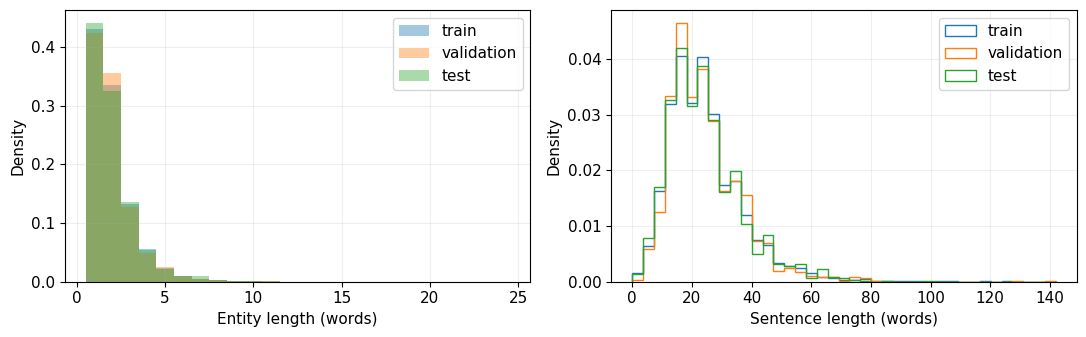

In [16]:
def io_span_lengths(ex):
    tags = io_to_bio(ex['ner_tags'], ex['fine_ner_tags'])
    spans, current = [], None
    for i, t in enumerate(tags + ['O']):
        if current is not None and (t == 'O' or t.startswith('B-') or t[2:] != current[1]):
            spans.append((current[0], i, current[1]))
            current = None
        if t != 'O' and current is None:
            current = (i, t[2:])
    return spans


dataset_stats = {}
for split, ds in source_subset.items():
    count, span_lengths, sentence_lengths = collections.Counter(), [], []
    for ex in ds:
        spans = io_span_lengths(ex)
        count.update(t for _, _, t in spans)
        span_lengths.extend(b - a for a, b, _ in spans)
        sentence_lengths.append(len(ex['tokens']))
    dataset_stats[split] = dict(n_sentences=len(ds), entities=dict(count),
        span_lengths=span_lengths, sentence_lengths=sentence_lengths,
        mean_span_length=float(np.mean(span_lengths)),
        mean_sentence_length=float(np.mean(sentence_lengths)),
        p95_sentence_length=float(np.percentile(sentence_lengths, 95)))
print('Число сущностей по типам:')
print(f'{"type":<16}' + ''.join(f'{s:>14}' for s in dataset_stats))
for typ in COARSE_NAMES[1:]:
    print(f'{typ:<16}' + ''.join(f'{v["entities"].get(typ, 0):>14,}' for v in dataset_stats.values()))
for split, v in dataset_stats.items():
    print(split, 'mean span words:', round(v['mean_span_length'], 2),
          'mean sentence:', round(v['mean_sentence_length'], 2), 'p95:', v['p95_sentence_length'])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
span_bins = np.arange(.5, max(max(v['span_lengths']) for v in dataset_stats.values()) + 1.5)
sentence_bins = np.linspace(0, max(max(v['sentence_lengths']) for v in dataset_stats.values()) + 1, 40)
for split, v in dataset_stats.items():
    axes[0].hist(v['span_lengths'], bins=span_bins, alpha=0.4, label=split, density=True)
    axes[1].hist(v['sentence_lengths'], bins=sentence_bins, histtype='step', label=split, density=True)
axes[0].set(xlabel='Entity length (words)', ylabel='Density')
axes[1].set(xlabel='Sentence length (words)', ylabel='Density')
for ax in axes: ax.legend(); ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(ARTIFACTS / 'data_lengths.png', dpi=150)
plt.show()
(ARTIFACTS / 'dataset_stats.json').write_text(json.dumps(dataset_stats, indent=2))


**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** Few-NERD (Ding et al., ACL 2021) — английские предложения Wikipedia с ручной разметкой 8 крупных и 66 детальных типов. Используется supervised-конфигурация и 8 крупных типов: art, building, event, location, organization, other, person, product; лицензия карточки — CC BY-SA 4.0. Берем заранее фиксированное подмножество официальных сплитов, не переносим предложения между ними и исключаем точные дубликаты с учетом регистра. Это не гарантирует независимости по статьям: DOCSTART/идентификаторы документов в источнике отсутствуют, поэтому близкие предложения и знакомые сущности могут оставаться.

Исходная IO-разметка не содержит отдельных B-тегов. Для начала нового спана используем смену fine-типа, а затем объединяем типы в coarse; так сохраняются границы соседних сущностей разных fine-типов при одном coarse-типе. Соседние сущности с одинаковым fine-типом восстановить однозначно нельзя — это ограничение источника, а не повод изобретать границу. Дисбаланс типов, длинные имена и усечение контекста могут ухудшать качество; статистика выбранных данных приведена выше.


In [17]:
rare_type = min(dataset_stats['train']['entities'], key=dataset_stats['train']['entities'].get)
display(Markdown(f'В train реже всего **{rare_type}**: '
    f'**{dataset_stats["train"]["entities"][rare_type]}** сущностей. '
    f'Средняя длина спана — **{dataset_stats["train"]["mean_span_length"]:.2f}** слова, '
    f'предложения — **{dataset_stats["train"]["mean_sentence_length"]:.2f}** слова.'))


В train реже всего **art**: **801** сущностей. Средняя длина спана — **1.99** слова, предложения — **24.57** слова.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [18]:
def bio_to_spans(tags):
    spans, start, current_type = [], None, None
    for i, tag in enumerate(list(tags) + ['O']):
        if tag == 'O':
            prefix, typ = 'O', None
        else:
            if '-' not in tag or tag.split('-', 1)[0] not in {'B', 'I'}:
                raise ValueError(f'Не BIO-тег: {tag}')
            prefix, typ = tag.split('-', 1)
            if not typ:
                raise ValueError('Пустой тип сущности')
        if start is not None and (prefix != 'I' or typ != current_type):
            spans.append((start, i, current_type))
            start, current_type = None, None
        if prefix != 'O' and start is None:
            start, current_type = i, typ
    return spans


def spans_to_bio(spans, n_words):
    if n_words < 0:
        raise ValueError('n_words должен быть неотрицательным')
    tags = ['O'] * n_words
    for start, end, typ in spans:
        if not (0 <= start < end <= n_words) or not typ:
            raise ValueError(f'Невалидный спан: {(start, end, typ)}')
        if any(t != 'O' for t in tags[start:end]):
            raise ValueError('BIO не поддерживает пересекающиеся или вложенные спаны')
        tags[start:end] = ['B-' + typ] + ['I-' + typ] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    labels, seen = [], set()
    for word_id in word_ids:
        if word_id is None:
            labels.append(-100)
            continue
        if not 0 <= word_id < len(word_labels):
            raise ValueError(f'word_id вне диапазона: {word_id}')
        label = int(word_labels[word_id])
        if word_id not in seen:
            labels.append(label)
            seen.add(word_id)
        else:
            labels.append(-100 if b_to_i is None else b_to_i.get(label, label))
    return labels


In [19]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [20]:
# IO -> BIO проверяется отдельно на переходах и реальных примерах.
loc, building = COARSE_NAMES.index('location'), COARSE_NAMES.index('building')
assert io_to_bio([loc, loc, 0, loc], [21, 21, 0, 21]) == [
    'B-location', 'I-location', 'O', 'B-location']
assert io_to_bio([loc, loc], [21, 22]) == ['B-location', 'B-location']
assert io_to_bio([], []) == []

conversion_stats = {}
Path('data').mkdir(exist_ok=True)
for split, ds in raw.items():
    path = Path('data') / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as f:
        for ex in ds:
            tags = [LABEL_NAMES[i] for i in ex['ner_tags']]
            f.write(json.dumps({'tokens': ex['tokens'], 'spans': bio_to_spans(tags)}, ensure_ascii=False) + '\n')
    changed = 0
    with path.open(encoding='utf-8') as f:
        for ex, line in zip(ds, f, strict=True):
            obj = json.loads(line)
            assert obj['tokens'] == ex['tokens']
            original_tags = [LABEL_NAMES[i] for i in ex['ner_tags']]
            back = spans_to_bio(obj['spans'], len(obj['tokens']))
            changed += back != original_tags
            assert bio_to_spans(back) == bio_to_spans(original_tags)
            assert back == original_tags
    conversion_stats[split] = {'checked': len(ds), 'noncanonical_bio': changed}
    print(split, conversion_stats[split])

for i in [0, 1, 2]:
    ex = raw['train'][i]
    tags = [LABEL_NAMES[t] for t in ex['ner_tags']]
    print('WORDS:', ' '.join(ex['tokens']))
    print('BIO:  ', list(zip(ex['tokens'], tags)))
    print('SPANS:', [(a, b, t, ' '.join(ex['tokens'][a:b])) for a, b, t in bio_to_spans(tags)])


train {'checked': 8000, 'noncanonical_bio': 0}
validation {'checked': 1500, 'noncanonical_bio': 0}
test {'checked': 1500, 'noncanonical_bio': 0}
WORDS: Several bands of Nez Perce actively resisted attempts to restrict them to reservation .
BIO:   [('Several', 'O'), ('bands', 'O'), ('of', 'O'), ('Nez', 'B-organization'), ('Perce', 'I-organization'), ('actively', 'O'), ('resisted', 'O'), ('attempts', 'O'), ('to', 'O'), ('restrict', 'O'), ('them', 'O'), ('to', 'O'), ('reservation', 'O'), ('.', 'O')]
SPANS: [(3, 5, 'organization', 'Nez Perce')]
WORDS: MMA 's Labrie , Demaître , Harding , Grindrod , Labonté , Strout and Horan faced a Canadian federal Fisheries Act charge , with a potential maximum penalty of $ 1-million fine , for `` the crude oil that flowed into Lac-Mégantic and the Chaudière River after the accident . ''
BIO:   [('MMA', 'B-organization'), ("'s", 'O'), ('Labrie', 'B-location'), (',', 'O'), ('Demaître', 'B-location'), (',', 'O'), ('Harding', 'B-location'), (',', 'O'), ('Gr

In [21]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 8000
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1500
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1500
    })
})
ENTITY_TYPES ['art', 'building', 'event', 'location', 'organization', 'other', 'person', 'product']
train: проверено 7985 предложений, обрезано по MAX_LENGTH 15, слов без сабвордов или за обрезкой 258
[CLS]            None  -100
several             0  O
bands               1  O
of                  2  O
ne                  3  B-organization
##z                 3  -100
per                 4  I-organization
##ce                4  -100
actively            5  O
resisted            6  O
attempts            7  O
to                  8  O
restrict            9  O
them               10  O
to                 11  O
reservation        12  O
.                  13  O
[SEP]            None  -100


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** При метке только на первом сабворде длинное слово не получает больший вес в loss только потому, что токенизатор разбил его на много частей. `-100` — `ignore_index` для cross-entropy: такие позиции, включая padding и спецтокены, не участвуют в оптимизации. Оценка при этом идет по всем исходным словам и сущностям; слова за границей `MAX_LENGTH` получают `O`, поэтому усечение может снижать recall. Сначала IO преобразуется в BIO с учетом fine-типов, затем проверяется JSON round-trip и выравнивание на настоящем токенизаторе; вложенность не поддерживается, пересекающиеся спаны явно отклоняются.


In [22]:
truncation_stats = {}
for split, ds in data.items():
    affected, missing, cut_entity_words, empty_token_words = 0, 0, 0, 0
    for ex in ds:
        full_enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=False)
        short_enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
        full_seen = set(full_enc.word_ids()) - {None}
        short_seen = set(short_enc.word_ids()) - {None}
        lost = set(range(len(ex['tokens']))) - short_seen
        affected += len(full_enc['input_ids']) > MAX_LENGTH
        missing += len(lost)
        empty_token_words += len(ex['tokens']) - len(full_seen)
        cut_entity_words += sum(LABEL_NAMES[ex['ner_tags'][w]] != 'O' for w in lost)
    truncation_stats[split] = dict(truncated=affected, missing_words=missing,
        missing_entity_words=cut_entity_words, words_without_subtokens=empty_token_words)
print('Точная проверка усечения (а не только len == MAX_LENGTH):', truncation_stats)
display(Markdown(f'В текущем train реально обрезано **{truncation_stats["train"]["truncated"]}** '
    f'предложений; слов без доступного сабворда **{truncation_stats["train"]["missing_words"]}**, '
    f'из них слов без сабвордов даже до усечения **{truncation_stats["train"]["words_without_subtokens"]}**. '
    f'JSON round-trip проверен для **{sum(v["checked"] for v in conversion_stats.values())}** '
    f'предложений, неканонических BIO после IO-конвертации **'
    f'{sum(v["noncanonical_bio"] for v in conversion_stats.values())}**.'))


Точная проверка усечения (а не только len == MAX_LENGTH): {'train': {'truncated': 15, 'missing_words': 258, 'missing_entity_words': 53, 'words_without_subtokens': 0}, 'validation': {'truncated': 3, 'missing_words': 82, 'missing_entity_words': 24, 'words_without_subtokens': 0}, 'test': {'truncated': 2, 'missing_words': 13, 'missing_entity_words': 0, 'words_without_subtokens': 0}}


В текущем train реально обрезано **15** предложений; слов без доступного сабворда **258**, из них слов без сабвордов даже до усечения **0**. JSON round-trip проверен для **11000** предложений, неканонических BIO после IO-конвертации **0**.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [23]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [24]:
def fit_majority_tagger(tokens_list, tags_list):
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list, strict=True):
        for word, tag in zip(words, tags, strict=True):
            counts[word][tag] += 1
    # При равенстве частот — лексикографический порядок, т.е. воспроизводимый tie-break.
    return {word: min(c, key=lambda tag: (-c[tag], tag)) for word, c in counts.items()}


def predict_majority(tagger, words):
    return [tagger.get(word, 'O') for word in words]


In [25]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_tags = [[LABEL_NAMES[i] for i in row] for row in data['train']['ner_tags']]
majority_tagger = fit_majority_tagger(data['train']['tokens'], train_tags)
majority_pred = [predict_majority(majority_tagger, ws) for ws in val_tokens]
set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline = {'majority': entity_scores(val_gold, majority_pred),
            'random_head': entity_scores(val_gold, random_pred)}
oov_rate = sum(w not in majority_tagger for ws in val_tokens for w in ws) / sum(map(len, val_tokens))
print(json.dumps(baseline, indent=2))
print('validation OOV:', round(oov_rate, 4))
del random_model
gc.collect()


{
  "majority": {
    "f1_micro": 0.2033195020746888,
    "f1_macro": 0.1326726196971981,
    "precision": 0.19678714859437751,
    "recall": 0.21030042918454936
  },
  "random_head": {
    "f1_micro": 0.010730885610007176,
    "f1_macro": 0.00772032127447801,
    "precision": 0.006121867881548975,
    "recall": 0.043423377934864935
  }
}
validation OOV: 0.1152
Out[25]: 33


Loading weights: 100%|##########| 69/69 [00:00<00:00, 10736.67it/s]


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** Словарь обучен только на train и использует частоты тегов для точного написания слова; незнакомые слова получают `O`. Повторяющиеся имена помогают, но словарь не учитывает контекст, омонимию и совместную границу нескольких слов. Предобучение энкодера дает языковые признаки, но случайная линейная голова еще не связывает их с нашими 17 тегами: без NER-обучения правильные спаны в основном случайны.


In [26]:
display(Markdown(f'На validation словарный entity F1 = **{baseline["majority"]["f1_micro"]:.4f}**, '
    f'случайная голова — **{baseline["random_head"]["f1_micro"]:.4f}**; '
    f'доля незнакомых слов для словаря — **{oov_rate:.1%}**. '
    'Сравнение финальной модели со словарем ниже выполняется на том же validation.'))


На validation словарный entity F1 = **0.2033**, случайная голова — **0.0107**; доля незнакомых слов для словаря — **11.5%**. Сравнение финальной модели со словарем ниже выполняется на том же validation.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [27]:
LR = 3e-4
BATCH_SIZE = 32


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    tok = tok or tokenizer
    # Сначала явно восстанавливаем флаги, чтобы повторный вызов не наследовал заморозку.
    for p in model.parameters():
        p.requires_grad_(True)
    if freeze_encoder:
        for p in model.base_model.parameters():
            p.requires_grad_(False)
    steps = max(1, math.ceil(len(train_ds) / batch_size) * math.ceil(epochs))
    log_interval = max(1, steps // 12)
    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=epochs,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size * 2,
        warmup_steps=math.ceil(0.1 * steps),
        weight_decay=0.01,
        lr_scheduler_type='linear',
        optim='adamw_torch',
        eval_strategy='steps', eval_steps=log_interval,
        logging_strategy='steps', logging_steps=log_interval,
        save_strategy='no', report_to='none', disable_tqdm=True,
        seed=SEED, data_seed=SEED, full_determinism=True,
        dataloader_num_workers=0, dataloader_pin_memory=device.type == 'cuda',
        fp16=device.type == 'cuda', use_cpu=device.type == 'cpu',
    )
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
        processing_class=tok,
        data_collator=DataCollatorForTokenClassification(tok, pad_to_multiple_of=8))
    if device.type == 'cuda': torch.cuda.synchronize()
    started = time.perf_counter()
    trainer.train()
    trainer.evaluate()  # последняя точка, даже когда число шагов не кратно eval_steps
    if device.type == 'cuda': torch.cuda.synchronize()
    seconds = time.perf_counter() - started
    result = copy.deepcopy(trainer.state.log_history)
    del trainer
    return result, seconds


{'loss': '1.301', 'grad_norm': '1.454', 'learning_rate': '0.000244', 'epoch': '0.248'}
{'eval_loss': '0.6231', 'eval_runtime': '5.469', 'eval_samples_per_second': '274.3', 'eval_steps_per_second': '4.388', 'epoch': '0.248'}
{'loss': '0.5156', 'grad_norm': '2.207', 'learning_rate': '0.0002787', 'epoch': '0.496'}
{'eval_loss': '0.4026', 'eval_runtime': '5.406', 'eval_samples_per_second': '277.5', 'eval_steps_per_second': '4.439', 'epoch': '0.496'}
{'loss': '0.3837', 'grad_norm': '1.572', 'learning_rate': '0.0002511', 'epoch': '0.744'}
{'eval_loss': '0.3345', 'eval_runtime': '5.513', 'eval_samples_per_second': '272.1', 'eval_steps_per_second': '4.354', 'epoch': '0.744'}
{'loss': '0.3474', 'grad_norm': '1.764', 'learning_rate': '0.0002236', 'epoch': '0.992'}
{'eval_loss': '0.3199', 'eval_runtime': '5.841', 'eval_samples_per_second': '256.8', 'eval_steps_per_second': '4.109', 'epoch': '0.992'}
{'loss': '0.2505', 'grad_norm': '1.614', 'learning_rate': '0.000196', 'epoch': '1.24'}
{'eval_loss

Loading weights: 100%|##########| 69/69 [00:00<00:00, 14781.50it/s]


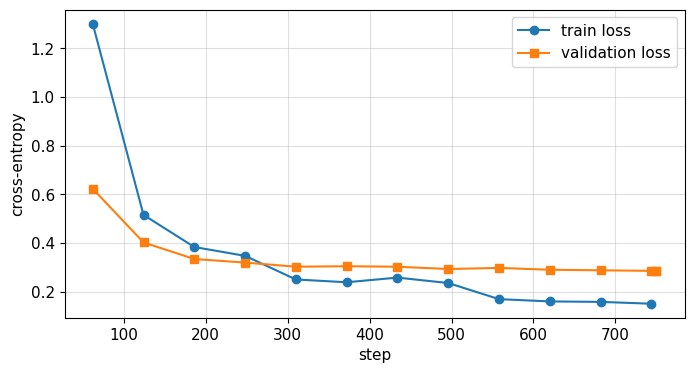

In [28]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

In [29]:
fig = plt.gcf()
# Исходная ячейка уже показала график: сохраняем явную независимую копию.
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(*zip(*train_curve), 'o-', label='train')
ax.plot(*zip(*eval_curve), 's-', label='validation')
ax.set(xlabel='Step', ylabel='Cross-entropy')
ax.legend(); ax.grid(alpha=.3); fig.tight_layout()
fig.savefig(ARTIFACTS / 'learning_curves.png', dpi=150)
plt.close(fig)
(ARTIFACTS / 'history_main.json').write_text(json.dumps(history, indent=2))


Out[29]: 4742


<Figure size 640x480 with 0 Axes>

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** Learning rate 3e-4 входит в диапазон, проверявшийся авторами BERT Miniatures для небольших моделей; для большого BERT он мог бы быть чрезмерным. Batch 32 ограничивает память, 3 эпохи — фиксированный учебный бюджет, 10% warmup смягчает старт с новой головой, weight decay 0.01 дает регуляризацию; линейно уменьшаем LR до нуля. Динамический padding экономит вычисления. FP16 включается только на CUDA, CPU работает в FP32. Чекпойнты не выбираются по test, основная и абляционная модели сравниваются после одинакового числа эпох.


In [30]:
best_loss = min(v for _, v in eval_curve)
last_loss = eval_curve[-1][1]
display(Markdown(f'Обучение заняло **{train_seconds:.1f} с** на **{DEVICE_NAME}**. '
    f'Последний train loss **{train_curve[-1][1]:.4f}**, validation loss **{last_loss:.4f}**, '
    f'минимальный validation loss **{best_loss:.4f}**. ' +
    ('К концу validation loss вырос относительно минимума: это признак возможного переобучения; '
     'следующий опыт — early stopping по validation.' if last_loss > best_loss * 1.03 else
     'Заметного роста validation loss к концу нет; дополнительные эпохи нужно проверять отдельно по validation, '
     'снижение train loss само по себе не доказывает рост качества.')))


Обучение заняло **454.3 с** на **cpu**. Последний train loss **0.1509**, validation loss **0.2858**, минимальный validation loss **0.2858**. Заметного роста validation loss к концу нет; дополнительные эпохи нужно проверять отдельно по validation, снижение train loss само по себе не доказывает рост качества.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [31]:
def token_f1(gold, pred):
    tp = predicted = actual = 0
    for gs, ps in zip(gold, pred, strict=True):
        for g, p in zip(gs, ps, strict=True):
            tp += p != 'O' and p == g
            predicted += p != 'O'
            actual += g != 'O'
    return 2 * tp / (predicted + actual) if predicted + actual else 0.0


In [32]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

def full_report(gold, pred):
    report = classification_report(gold, pred, digits=4, output_dict=True, zero_division=0)
    return dict(**entity_scores(gold, pred), token_f1=token_f1(gold, pred),
                per_type={t: report[t] for t in ENTITY_TYPES if t in report})

val_pred, val_probs = predict_word_tags(model, val_tokens, return_probs=True)
val_final = full_report(val_gold, val_pred)
test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in row] for row in data['test']['ner_tags']]
test_pred = predict_word_tags(model, test_tokens)
final = full_report(test_gold, test_pred)
for split, gold, pred in [('validation', val_gold, val_pred), ('test', test_gold, test_pred)]:
    print('\n' + split.upper())
    print(classification_report(gold, pred, digits=4, zero_division=0))
    print('token F1:', round(token_f1(gold, pred), 4))



VALIDATION
              precision    recall  f1-score   support

         art     0.4842    0.4920    0.4881       187
    building     0.5247    0.5498    0.5370       251
       event     0.4649    0.5584    0.5074       154
    location     0.7187    0.7939    0.7544      1155
organization     0.5524    0.5524    0.5524       715
       other     0.4987    0.5107    0.5046       374
      person     0.7722    0.8626    0.8149       888
     product     0.3904    0.4135    0.4016       237

   micro avg     0.6306    0.6774    0.6531      3961
   macro avg     0.5508    0.5917    0.5701      3961
weighted avg     0.6270    0.6774    0.6509      3961

token F1: 0.7323

TEST
              precision    recall  f1-score   support

         art     0.6234    0.6400    0.6316       150
    building     0.5070    0.5192    0.5131       208
       event     0.4076    0.4433    0.4247       194
    location     0.7409    0.8159    0.7766      1097
organization     0.5219    0.5687    0.5443

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** Micro F1 агрегирует TP/FP/FN всех типов, поэтому частые типы влияют сильнее; macro F1 усредняет F1 типов с одинаковым весом. Словный F1 учитывает отдельные верные BIO-теги, а entity F1 требует точного совпадения обеих границ и типа всего спана: частично правильное многословное имя не считается верной сущностью. Для извлечения имен в приложении ближе entity F1; словный F1 полезен для диагностики. Низкий F1 типа не доказывает единственную причину: ниже сопоставлены частота и длины, но для причинного вывода нужен дополнительный опыт.


В сохраненном финальном запуске location и person дают **1916/3778 (50.7%)** истинных сущностей, их F1 — **0.7766** и **0.8216**. Высокое качество этих частых типов объясняет, почему micro F1 **0.6603** выше равновесного по типам macro F1 **0.5881**.


На test micro F1 **0.6603**, macro F1 **0.5881**, словный F1 **0.7387** (разность с entity F1 **+0.0783**). Хуже всего **event**, F1 **0.4247**, support на test **194**. В выбранном train у этого типа **857** спанов, их средняя длина **2.87** слова. Редкость, разнообразие названий и неоднозначный контекст — возможные объяснения ошибок, но их вклад этим измерением не разделен.

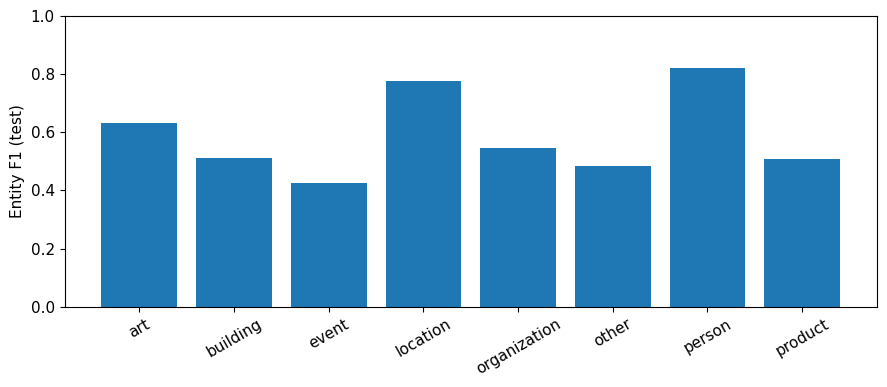

In [33]:
worst = min(final['per_type'], key=lambda t: final['per_type'][t]['f1-score'])
type_lengths = collections.defaultdict(list)
for ex in data['train']:
    for a, b, typ in bio_to_spans([LABEL_NAMES[x] for x in ex['ner_tags']]):
        type_lengths[typ].append(b-a)
display(Markdown(f'На test micro F1 **{final["f1_micro"]:.4f}**, macro F1 **{final["f1_macro"]:.4f}**, '
    f'словный F1 **{final["token_f1"]:.4f}** (разность с entity F1 '
    f'**{final["token_f1"]-final["f1_micro"]:+.4f}**). '
    f'Хуже всего **{worst}**, F1 **{final["per_type"][worst]["f1-score"]:.4f}**, '
    f'support на test **{final["per_type"][worst]["support"]}**. '
    f'В выбранном train у этого типа **{len(type_lengths[worst])}** спанов, '
    f'их средняя длина **{np.mean(type_lengths[worst]):.2f}** слова. '
    'Редкость, разнообразие названий и неоднозначный контекст — возможные объяснения ошибок, '
    'но их вклад этим измерением не разделен.'))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(ENTITY_TYPES, [final['per_type'][t]['f1-score'] for t in ENTITY_TYPES])
ax.set(ylim=(0, 1), ylabel='Entity F1 (test)')
ax.tick_params(axis='x', rotation=30); fig.tight_layout()
fig.savefig(ARTIFACTS / 'f1_per_type.png', dpi=150)
plt.show()


---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [34]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    gold_spans = [tuple(s) for s in gold_spans]
    pred_spans = [tuple(s) for s in pred_spans]
    def overlaps(a, b):
        return max(a[0], b[0]) < min(a[1], b[1])

    def best_overlap(gold, candidates):
        # Детерминированно: максимальная длина пересечения, затем близость границ.
        return min(candidates, key=lambda p: (
            -(min(gold[1], p[1]) - max(gold[0], p[0])),
            abs(gold[0] - p[0]) + abs(gold[1] - p[1]), p))

    result = []
    for gold in gold_spans:
        if gold in pred_spans:
            result.append(('correct', gold, gold))
            continue
        hits = [p for p in pred_spans if overlaps(gold, p)]
        same_type = [p for p in hits if p[2] == gold[2]]
        if same_type:
            result.append(('boundary', gold, best_overlap(gold, same_type)))
        elif hits:
            result.append(('type', gold, best_overlap(gold, hits)))
        else:
            result.append(('missed', gold, None))
    for pred in pred_spans:
        if not any(overlaps(gold, pred) for gold in gold_spans):
            result.append(('spurious', None, pred))
    return result


Категории: {'correct': 2683, 'boundary': 442, 'type': 572, 'missed': 264, 'spurious': 387}
Доли среди ошибок: {'boundary': 0.2655, 'type': 0.3435, 'missed': 0.1586, 'spurious': 0.2324}

 boundary | `` Puirt à beul `` has sometimes been used for dancing when no instruments were available .
GOLD: {'start': 1, 'end': 4, 'type': 'art', 'text': 'Puirt à beul'} | PRED: {'start': 2, 'end': 3, 'type': 'art', 'text': 'à'}

 boundary | Domenico dell'Allio ( 1505–1563 ) was an Italian Renaissance architect , working mostly in what was then Inner Austria , present-day Slovenia and the Austrian states of Styria and Carinthia .
GOLD: {'start': 17, 'end': 19, 'type': 'location', 'text': 'Inner Austria'} | PRED: {'start': 18, 'end': 19, 'type': 'location', 'text': 'Austria'}

 boundary | First Air Flight 6560 was a domestic charter flight that crashed on landing at Resolute , Nunavut , Canada , on 20 August 2011 .
GOLD: {'start': 2, 'end': 4, 'type': 'product', 'text': 'Flight 6560'} | PRED: {'start':

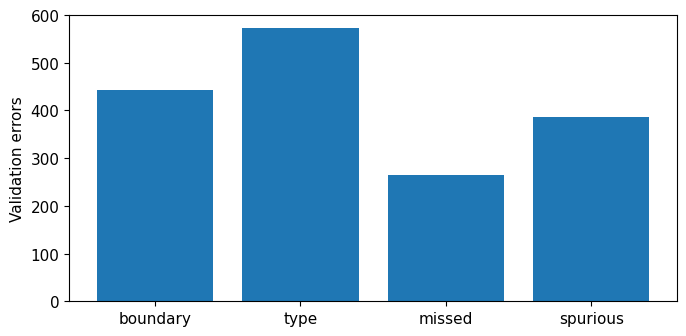

In [35]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

counts = collections.Counter({cat: 0 for cat in ERROR_CATEGORIES})
error_examples = collections.defaultdict(list)
for sent_id, (words, gs, ps) in enumerate(zip(val_tokens, val_gold, val_pred, strict=True)):
    for cat, gspan, pspan in categorize_errors(bio_to_spans(gs), bio_to_spans(ps)):
        counts[cat] += 1
        if cat != 'correct' and len(error_examples[cat]) < 5:
            def span_dict(span):
                return None if span is None else dict(start=span[0], end=span[1],
                    type=span[2], text=' '.join(words[span[0]:span[1]]))
            error_examples[cat].append(dict(sentence_id=sent_id, sentence=' '.join(words),
                category=cat, gold=span_dict(gspan), pred=span_dict(pspan)))
errors = dict(counts)
n_errors = sum(v for k, v in errors.items() if k != 'correct')
print('Категории:', errors)
print('Доли среди ошибок:', {k: round(v / max(1, n_errors), 4) for k, v in errors.items() if k != 'correct'})
for cat, examples in error_examples.items():
    for row in examples:
        print('\n', cat, '|', row['sentence'])
        print('GOLD:', row['gold'], '| PRED:', row['pred'])
assert sum(map(len, error_examples.values())) >= 5
(ARTIFACTS / 'error_examples.json').write_text(json.dumps(dict(error_examples), ensure_ascii=False, indent=2))
fig, ax = plt.subplots(figsize=(7, 3.5))
cats = ERROR_CATEGORIES[1:]
ax.bar(cats, [errors[c] for c in cats]); ax.set(ylabel='Validation errors')
fig.tight_layout(); fig.savefig(ARTIFACTS / 'error_categories.png', dpi=150)
plt.show()


**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** При ошибке границы модель обычно берет лишь часть названия либо захватывает соседнее слово; при ошибке типа находит имя, но смешивает семантические группы. Пропуск означает отсутствие пересекающегося предсказания, лишний спан — отсутствие пересекающейся разметки. Категории реализуют контракт задания, а не взаимно однозначное сопоставление для F1: один широкий предсказанный спан может пересекаться с двумя истинными. Поэтому суммы категорий нельзя подставлять в формулу precision/recall вместо `seqeval`.

Несовпадение с gold само по себе не доказывает ошибку аннотатора. Для примеров ниже я показываю контекст и обе границы; спорные места следует сверять с инструкцией и исходной статьей. Ни одна метка validation/test не исправлялась для улучшения метрик. Возможные неполные имена, описательные сочетания и неоднозначные типы — кандидаты на проверку, а не автоматически признанные ошибки разметки.


**Ручной разбор примеров сохраненного финального запуска:**

| Категория | Gold | Предсказание | Интерпретация |
|---|---|---|---|
| boundary | Puirt à beul | à | Модель выделила только внутреннее слово многословного названия. |
| boundary | Inner Austria | Austria | Тип места сохранен, но потерян первый компонент географического имени. |
| type | French | French | Одинаковые границы, но location заменен на product; рядом стоит название автомобиля. |
| type | Cannes | Cannes Lions | Одновременно неверны тип и граница: название в контексте фестиваля неоднозначно. По контракту это type, поскольку нет пересечения того же типа. |
| missed | The Wannadies | — | Сущность organization из gold полностью пропущена; словарного знания без уверенного контекста недостаточно. |
| missed | Renaissance | — | Историческое название с меткой event принято за фон; такие события разнообразнее стандартных имен людей. |
| spurious | — | Küchen | В gold этого предложения все слова O. По контексту это кандидат на неполную разметку, а не доказанная ошибка модели. |
| spurious | — | Paul Friedrich von Mecklenburg-Schwerin | Контекст Grand Duke указывает на имя человека, но gold-спана нет. Это кандидат на пропуск аннотации; исходник и инструкция не проверялись, gold не изменялся. |

Указания на неполную разметку — гипотезы для проверки; метрики рассчитаны по исходному gold без исправлений.


In [36]:
dominant_error = max(ERROR_CATEGORIES[1:], key=lambda c: errors[c])
actions = {
    'missed': 'сначала проверить recall редких типов и влияние усечения, затем увеличить train и сравнить более крупный cased-энкодер',
    'boundary': 'проверить многословные имена и IO-конвертацию; сравнить обучение на всех сабвордах и структурированное декодирование',
    'type': 'построить матрицу путаницы типов и добавить train-примеры неоднозначных контекстов',
    'spurious': 'проверить ложные имена на фоне и порог уверенности только по validation',
}
display(Markdown(f'Чаще всего встречается **{dominant_error}**: '
    f'**{errors[dominant_error]} / {n_errors} ({errors[dominant_error]/max(1,n_errors):.1%})** ошибок. '
    f'Следующий шаг: {actions[dominant_error]}.'))


Чаще всего встречается **type**: **572 / 1665 (34.4%)** ошибок. Следующий шаг: построить матрицу путаницы типов и добавить train-примеры неоднозначных контекстов.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [37]:
ABLATION = 'freeze'
set_seed(SEED)
frozen_model = make_model()
frozen_history, frozen_seconds = train_ner(model=frozen_model,
    train_ds=tokenized['train'], eval_ds=tokenized['validation'],
    freeze_encoder=True, out_dir='runs/freeze')
frozen_pred = predict_word_tags(frozen_model, val_tokens)
ablation = dict(setting=ABLATION, split='validation', epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE,
    full=dict(**entity_scores(val_gold, val_pred), seconds=train_seconds,
              trainable_params=sum(p.numel() for p in model.parameters() if p.requires_grad)),
    frozen=dict(**entity_scores(val_gold, frozen_pred), seconds=frozen_seconds,
                trainable_params=sum(p.numel() for p in frozen_model.parameters() if p.requires_grad)))
RUN_TIMES['train_frozen_sec'] = frozen_seconds
print(json.dumps(ablation, indent=2))
(ARTIFACTS / 'history_freeze.json').write_text(json.dumps(frozen_history, indent=2))
del frozen_model
gc.collect()


{'loss': '2.52', 'grad_norm': '4.588', 'learning_rate': '0.000244', 'epoch': '0.248'}
{'eval_loss': '2.004', 'eval_runtime': '6.662', 'eval_samples_per_second': '225.2', 'eval_steps_per_second': '3.603', 'epoch': '0.248'}
{'loss': '1.4', 'grad_norm': '1.05', 'learning_rate': '0.0002787', 'epoch': '0.496'}
{'eval_loss': '0.9931', 'eval_runtime': '5.384', 'eval_samples_per_second': '278.6', 'eval_steps_per_second': '4.458', 'epoch': '0.496'}
{'loss': '0.8759', 'grad_norm': '0.5355', 'learning_rate': '0.0002511', 'epoch': '0.744'}
{'eval_loss': '0.8006', 'eval_runtime': '5.228', 'eval_samples_per_second': '286.9', 'eval_steps_per_second': '4.591', 'epoch': '0.744'}
{'loss': '0.7777', 'grad_norm': '0.4609', 'learning_rate': '0.0002236', 'epoch': '0.992'}
{'eval_loss': '0.7208', 'eval_runtime': '6.677', 'eval_samples_per_second': '224.7', 'eval_steps_per_second': '3.595', 'epoch': '0.992'}
{'loss': '0.7028', 'grad_norm': '0.42', 'learning_rate': '0.000196', 'epoch': '1.24'}
{'eval_loss': '0

Loading weights: 100%|##########| 69/69 [00:00<00:00, 14647.58it/s]


**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** В абляции меняется только возможность обновлять энкодер: те же начальные веса и seed, данные, LR, batch, warmup и число эпох. Замороженные признаки не адаптируются к нашим типам и границам, а маленькая случайная голова должна выучить их линейно; полное дообучение дает больше гибкости. Ускорение не обязано равняться отношению обучаемых параметров: forward энкодера остается и в замороженной модели, как и оценка validation. Это сравнение при одном бюджете, а не поиск лучшего LR для каждой настройки; для надежности нужны несколько seed и отдельный подбор LR по validation.


In [38]:
display(Markdown(f'На одном validation: полное дообучение F1 **{ablation["full"]["f1_micro"]:.4f}**, '
    f'замороженный энкодер **{ablation["frozen"]["f1_micro"]:.4f}**, '
    f'изменение **{ablation["frozen"]["f1_micro"]-ablation["full"]["f1_micro"]:+.4f}**. '
    f'Время **{train_seconds:.1f} → {frozen_seconds:.1f} с**, '
    f'обучаемые параметры **{ablation["full"]["trainable_params"]:,} → '
    f'{ablation["frozen"]["trainable_params"]:,}**.'))


На одном validation: полное дообучение F1 **0.6531**, замороженный энкодер **0.2911**, изменение **-0.3620**. Время **454.3 → 224.7 с**, обучаемые параметры **11,109,137 → 4,369**.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** Количественные выводы ниже формируются из текущего запуска; все F1 указаны в шкале 0–1. Сравнение до/после и абляция используют один validation, а итоговая оценка — отдельный test.


In [39]:
display(Markdown(
    f'1. На фиксированном Few-NERD-подмножестве **{len(data["train"])} / '
    f'{len(data["validation"])} / {len(data["test"])}** предложений проверены IO→BIO, '
    f'JSON round-trip и выравнивание по сабвордам.\n'
    f'2. На validation словарный F1 **{baseline["majority"]["f1_micro"]:.4f}**, '
    f'случайная голова **{baseline["random_head"]["f1_micro"]:.4f}**, '
    f'после обучения **{val_final["f1_micro"]:.4f}**.\n'
    f'3. Итог на test: micro F1 **{final["f1_micro"]:.4f}**, macro F1 '
    f'**{final["f1_macro"]:.4f}**, precision **{final["precision"]:.4f}**, '
    f'recall **{final["recall"]:.4f}**.\n'
    f'4. Словный F1 **{final["token_f1"]:.4f}** отличается от entity F1, '
    f'поскольку частично верный спан не дает зачета за сущность.\n'
    f'5. Чаще всего возникает **{dominant_error}** (**{errors[dominant_error]}** случаев); '
    f'самый слабый тип на test — **{worst}**.\n'
    f'6. Заморозка меняет validation F1 с **{ablation["full"]["f1_micro"]:.4f}** '
    f'до **{ablation["frozen"]["f1_micro"]:.4f}**, время с **{train_seconds:.1f}** '
    f'до **{frozen_seconds:.1f} с**.\n'
    '7. Ограничения: небольшое подмножество, один seed, uncased-модель, потеря части границ в IO '
    'и возможная близость предложений разных сплитов; это не оценка на всем официальном бенчмарке.\n'
    '8. Далее следует проверить несколько seed, cased-модель, увеличение train и MAX_LENGTH '
    'по validation; test не использовать для выбора настроек.'
))


1. На фиксированном Few-NERD-подмножестве **8000 / 1500 / 1500** предложений проверены IO→BIO, JSON round-trip и выравнивание по сабвордам.
2. На validation словарный F1 **0.2033**, случайная голова **0.0107**, после обучения **0.6531**.
3. Итог на test: micro F1 **0.6603**, macro F1 **0.5881**, precision **0.6342**, recall **0.6887**.
4. Словный F1 **0.7387** отличается от entity F1, поскольку частично верный спан не дает зачета за сущность.
5. Чаще всего возникает **type** (**572** случаев); самый слабый тип на test — **event**.
6. Заморозка меняет validation F1 с **0.6531** до **0.2911**, время с **454.3** до **224.7 с**.
7. Ограничения: небольшое подмножество, один seed, uncased-модель, потеря части границ в IO и возможная близость предложений разных сплитов; это не оценка на всем официальном бенчмарке.
8. Далее следует проверить несколько seed, cased-модель, увеличение train и MAX_LENGTH по validation; test не использовать для выбора настроек.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [40]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "google/bert_uncased_L-4_H-256_A-4", "revision": "387825ce42dbb39b87911cdf8e383ee3b25184f8", "dataset": "DFKI-SLT/few-nerd/supervised", "classes": ["art", "building", "event", "location", "organization", "other", "person", "product"], "n_train": 8000, "n_val": 1500, "n_test": 1500, "params_total": 11109137, "ablation": {"setting": "freeze", "split": "validation", "epochs": 3, "lr": 0.0003, "batch_size": 32, "full": {"f1_micro": 0.6531158714703019, "f1_macro": 0.5700536685539999, "precision": 0.6305522914218566, "recall": 0.6773542034839687, "seconds": 454.336591053000
final F1 micro 0.6603


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [41]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** Бонус 6.1 не выбран, новая ручная разметка не выполнялась.


## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [42]:
if '6.2' in BONUS_TASKS:
    ALT_MODEL_ID = 'google/bert_uncased_L-2_H-128_A-2'
    ALT_REVISION = '30b0a37ccaaa32f332884b96992754e246e48c5f'
    alt_tok = AutoTokenizer.from_pretrained(ALT_MODEL_ID, revision=ALT_REVISION,
                                           use_fast=True, do_lower_case=True)
    alt_data = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                        fn_kwargs={'tok': alt_tok})
    set_seed(SEED)
    alt_model = make_model(ALT_MODEL_ID, ALT_REVISION)
    alt_history, alt_seconds = train_ner(alt_model, alt_data['train'], alt_data['validation'],
                                       tok=alt_tok, out_dir='runs/alternative')
    alt_pred = predict_word_tags(alt_model, val_tokens, tok=alt_tok)

    def inference_benchmark(m, tok, words, dev, repeats=12):
        m.to(dev).eval()
        inputs = {k: v.to(dev) for k, v in tok(words, is_split_into_words=True,
                  padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors='pt').items()}
        def sync():
            if torch.device(dev).type == 'cuda': torch.cuda.synchronize()
            elif torch.device(dev).type == 'mps': torch.mps.synchronize()
        with torch.inference_mode():
            for _ in range(3): m(**inputs)
            sync()
            elapsed = []
            for _ in range(repeats):
                sync(); start = time.perf_counter(); m(**inputs); sync()
                elapsed.append((time.perf_counter() - start) * 1000)
        return dict(mean_ms=float(np.mean(elapsed)), median_ms=float(np.median(elapsed)),
                    std_ms=float(np.std(elapsed)), repeats=repeats,
                    batch_size=len(words), padded_subwords=int(inputs['input_ids'].shape[1]))

    benchmark_words = val_tokens[:16]
    alternative = dict(model=ALT_MODEL_ID, revision=ALT_REVISION, license='apache-2.0',
        split='validation', params=sum(p.numel() for p in alt_model.parameters()),
        main_params=sum(p.numel() for p in model.parameters()), train_seconds=alt_seconds,
        metrics=entity_scores(val_gold, alt_pred), main_metrics=entity_scores(val_gold, val_pred),
        inference_main=inference_benchmark(model, tokenizer, benchmark_words, device),
        inference_alt=inference_benchmark(alt_model, alt_tok, benchmark_words, device))
    print(json.dumps(alternative, indent=2))
    (ARTIFACTS / 'history_alternative.json').write_text(json.dumps(alt_history, indent=2))
    (ARTIFACTS / 'bonus_6_2.json').write_text(json.dumps(alternative, indent=2))
    del alt_model
    gc.collect()


{'loss': '1.73', 'grad_norm': '0.6838', 'learning_rate': '0.000244', 'epoch': '0.248'}
{'eval_loss': '1.043', 'eval_runtime': '1.092', 'eval_samples_per_second': '1373', 'eval_steps_per_second': '21.97', 'epoch': '0.248'}
{'loss': '0.8008', 'grad_norm': '0.8115', 'learning_rate': '0.0002787', 'epoch': '0.496'}
{'eval_loss': '0.6484', 'eval_runtime': '1.048', 'eval_samples_per_second': '1432', 'eval_steps_per_second': '22.9', 'epoch': '0.496'}
{'loss': '0.5871', 'grad_norm': '1.213', 'learning_rate': '0.0002511', 'epoch': '0.744'}
{'eval_loss': '0.5235', 'eval_runtime': '1.162', 'eval_samples_per_second': '1291', 'eval_steps_per_second': '20.66', 'epoch': '0.744'}
{'loss': '0.5201', 'grad_norm': '0.9597', 'learning_rate': '0.0002236', 'epoch': '0.992'}
{'eval_loss': '0.4595', 'eval_runtime': '1.151', 'eval_samples_per_second': '1303', 'eval_steps_per_second': '20.85', 'epoch': '0.992'}
{'loss': '0.4363', 'grad_norm': '1.352', 'learning_rate': '0.000196', 'epoch': '1.24'}
{'eval_loss': '

Loading weights: 100%|##########| 37/37 [00:00<00:00, 6067.29it/s]


**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** Сравниваются два английских uncased-энкодера одной серии: BERT-Mini (4×256) и BERT-Tiny (2×128), оба под Apache-2.0. Условия одинаковы: выбранные предложения, seed, 3 эпохи, LR, batch, MAX_LENGTH и word-level оценка. Для другой модели данные токенизируются ее собственным токенизатором. Задержка — forward без токенизации на одинаковом батче и устройстве после трех прогревов, 12 повторов с синхронизацией; измеряется распределение времени, а не один случайный запуск. Число параметров характеризует размер, но не является измерением пикового потребления RAM/VRAM.


In [43]:
if '6.2' in BONUS_TASKS:
    display(Markdown(f'BERT-Mini: F1 **{alternative["main_metrics"]["f1_micro"]:.4f}**, '
        f'параметры **{alternative["main_params"]:,}**, '
        f'обучение **{train_seconds:.1f} с**, forward **{alternative["inference_main"]["mean_ms"]:.2f} мс**. '
        f'BERT-Tiny: F1 **{alternative["metrics"]["f1_micro"]:.4f}**, '
        f'параметры **{alternative["params"]:,}**, обучение **{alt_seconds:.1f} с**, '
        f'forward **{alternative["inference_alt"]["mean_ms"]:.2f} мс**. '
        'Это сравнение при общем бюджете; оптимальные гиперпараметры моделей могут отличаться.'))


BERT-Mini: F1 **0.6531**, параметры **11,109,137**, обучение **454.3 с**, forward **56.01 мс**. BERT-Tiny: F1 **0.5068**, параметры **4,371,601**, обучение **95.9 с**, forward **10.80 мс**. Это сравнение при общем бюджете; оптимальные гиперпараметры моделей могут отличаться.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

{
  "clean": {
    "f1_micro": 0.6531158714703019,
    "f1_macro": 0.5700536685539999,
    "precision": 0.6305522914218566,
    "recall": 0.6773542034839687
  },
  "lowercase": {
    "f1_micro": 0.6531158714703019,
    "f1_macro": 0.5700536685539999,
    "precision": 0.6305522914218566,
    "recall": 0.6773542034839687
  },
  "uppercase": {
    "f1_micro": 0.6531158714703019,
    "f1_macro": 0.5700536685539999,
    "precision": 0.6305522914218566,
    "recall": 0.6773542034839687
  },
  "typos_20pct": {
    "f1_micro": 0.4237444798192462,
    "f1_macro": 0.3612276553633236,
    "precision": 0.3571675900277008,
    "recall": 0.520828073718758
  }
}


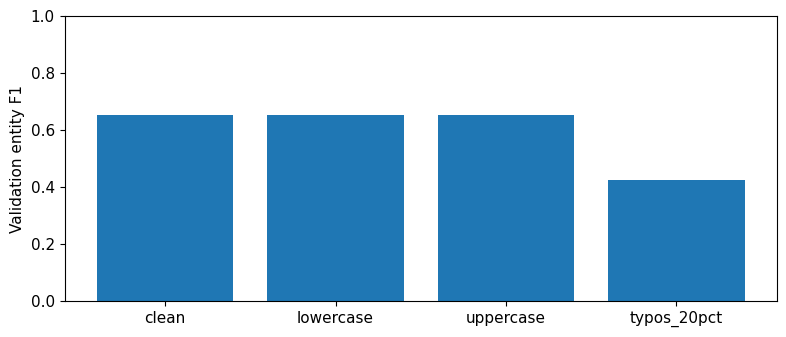

In [44]:
if '6.3' in BONUS_TASKS:
    def corrupt_typos(words, rng):
        result = []
        for word in words:
            positions = [i for i in range(len(word)-1) if word[i].isalpha() and word[i+1].isalpha()
                         and word[i] != word[i+1]]
            if positions and rng.random() < 0.2:
                i = rng.choice(positions)
                word = word[:i] + word[i+1] + word[i] + word[i+2:]
            result.append(word)
        return result

    rng = random.Random(SEED)
    shifted_inputs = {
        'lowercase': [[w.lower() for w in ws] for ws in val_tokens],
        'uppercase': [[w.upper() for w in ws] for ws in val_tokens],
        'typos_20pct': [corrupt_typos(ws, rng) for ws in val_tokens],
    }
    shift_results = {'clean': entity_scores(val_gold, val_pred)}
    for corruption, words in shifted_inputs.items():
        assert len(words) == len(val_tokens)
        assert all(len(a) == len(b) for a, b in zip(words, val_tokens, strict=True))
        pred = predict_word_tags(model, words)
        shift_results[corruption] = entity_scores(val_gold, pred)
    print(json.dumps(shift_results, indent=2))
    (ARTIFACTS / 'bonus_6_3.json').write_text(json.dumps(shift_results, indent=2))
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.bar(list(shift_results), [v['f1_micro'] for v in shift_results.values()])
    ax.set(ylabel='Validation entity F1', ylim=(0, 1))
    fig.tight_layout(); fig.savefig(ARTIFACTS / 'robustness.png', dpi=150)
    plt.show()


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** В lower/uppercase меняется только регистр, в опечатках с вероятностью 0.2 меняем местами две разные соседние буквы внутри слова. Слова не добавляются и не удаляются, поэтому индексы спанов и gold сохраняются. У uncased-токенизатора эффект регистра ожидаемо слабее, чем у cased-модели; при опечатках меняется WordPiece-разбиение и исчезают знакомые части имен. Это синтетический стресс-тест внутри одного домена: он не измеряет перенос Wikipedia→соцсети.


In [45]:
if '6.3' in BONUS_TASKS:
    hardest_shift = min(shifted_inputs, key=lambda k: shift_results[k]['f1_micro'])
    display(Markdown(f'Самый низкий F1 при **{hardest_shift}**: '
        f'**{shift_results[hardest_shift]["f1_micro"]:.4f}**, '
        f'чистые данные **{shift_results["clean"]["f1_micro"]:.4f}**, '
        f'падение **{shift_results["clean"]["f1_micro"]-shift_results[hardest_shift]["f1_micro"]:.4f}**.'))


Самый низкий F1 при **typos_20pct**: **0.4237**, чистые данные **0.6531**, падение **0.2294**.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [46]:
if '6.4' in BONUS_TASKS:
    import warnings
    # Динамическая INT8 на CPU; Embedding остается FP32.
    # Первый опыт со всеми Linear дал заметную потерю F1. Проверяем частичные
    # варианты по validation, заранее задавая допустимую потерю 0.005 F1.
    # Eager attention одинаков в FP32 и INT8, fused SDPA здесь не используется.
    cpu_reference = copy.deepcopy(model).cpu().eval()
    cpu_reference.set_attn_implementation('eager')
    cpu_preds = predict_word_tags(cpu_reference, val_tokens, dev=torch.device('cpu'))
    fp32_cpu_f1 = f1_score(val_gold, cpu_preds, zero_division=0)

    def state_size(m):
        buf = io.BytesIO()
        torch.save(m.state_dict(), buf)
        return buf.tell()

    fp32_latency = inference_benchmark(cpu_reference, tokenizer, val_tokens[:16], torch.device('cpu'))
    linears = {name: module for name, module in cpu_reference.named_modules()
               if isinstance(module, torch.nn.Linear)}
    last = cpu_reference.config.num_hidden_layers - 1
    ffn_names = [name for name in linears
                 if '.encoder.layer.' in name and '.attention.' not in name]
    candidates = {
        'all_linear': list(linears),
        'ffn_only': ffn_names,
        'last_ffn': [n for n in ffn_names if f'.layer.{last}.' in n],
        'last_output': [n for n in ffn_names if n.endswith(f'.layer.{last}.output.dense')],
    }
    MAX_F1_DROP = 0.005  # 0.5 процентного пункта; правило задается до перебора
    trials = {}
    for name, module_names in candidates.items():
        assert module_names, name
        qconfig = {n: torch.ao.quantization.default_dynamic_qconfig for n in module_names}
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', DeprecationWarning)
            candidate = torch.ao.quantization.quantize_dynamic(
                copy.deepcopy(cpu_reference), qconfig_spec=qconfig, dtype=torch.qint8, inplace=False)
        pred = predict_word_tags(candidate, val_tokens, dev=torch.device('cpu'))
        score = f1_score(val_gold, pred, zero_division=0)
        latency = inference_benchmark(candidate, tokenizer, val_tokens[:16], torch.device('cpu'))
        trials[name] = dict(f1=score, delta_f1=score-fp32_cpu_f1,
            within_budget=bool(score >= fp32_cpu_f1-MAX_F1_DROP),
            quantized_modules=module_names,
            quantized_linear_weights=sum(linears[n].weight.numel() for n in module_names),
            latency=latency, state_bytes=state_size(candidate),
            speedup=fp32_latency['mean_ms']/latency['mean_ms'])
        print(name, 'F1:', round(score, 4), 'speedup:', round(trials[name]['speedup'], 2),
              'within F1 budget:', trials[name]['within_budget'])
        del candidate
        gc.collect()
    acceptable = [name for name, trial in trials.items() if trial['within_budget']]
    assert acceptable, 'Ни один вариант не сохранил F1 в пределах 0.005: качество INT8 не подтверждено'
    # Выбираем максимальный объем квантизации в заданном бюджете качества,
    # а не минимальное шумное измерение задержки. Test для выбора не используется.
    selected = max(acceptable, key=lambda name: trials[name]['quantized_linear_weights'])
    chosen = trials[selected]
    quantization = dict(device='cpu', dtype='dynamic INT8 selected Linear; FP32 Embedding',
        selected=selected, max_f1_drop=MAX_F1_DROP, trials=trials,
        fp32_f1=fp32_cpu_f1, int8_f1=chosen['f1'], delta_f1=chosen['delta_f1'],
        fp32=fp32_latency, int8=chosen['latency'],
        fp32_state_bytes=state_size(cpu_reference), int8_state_bytes=chosen['state_bytes'],
        speedup=chosen['speedup'])
    print(json.dumps(quantization, indent=2))
    (ARTIFACTS / 'bonus_6_4.json').write_text(json.dumps(quantization, indent=2))
    del cpu_reference
    gc.collect()


all_linear F1: 0.6203 speedup: 1.81 within F1 budget: False
ffn_only F1: 0.6255 speedup: 1.15 within F1 budget: False
last_ffn F1: 0.6521 speedup: 1.01 within F1 budget: True
last_output F1: 0.6526 speedup: 1.0 within F1 budget: True
{
  "device": "cpu",
  "dtype": "dynamic INT8 selected Linear; FP32 Embedding",
  "selected": "last_ffn",
  "max_f1_drop": 0.005,
  "trials": {
    "all_linear": {
      "f1": 0.6202627589691764,
      "delta_f1": -0.03285311250112555,
      "within_budget": false,
      "quantized_modules": [
        "bert.encoder.layer.0.attention.self.query",
        "bert.encoder.layer.0.attention.self.key",
        "bert.encoder.layer.0.attention.self.value",
        "bert.encoder.layer.0.attention.output.dense",
        "bert.encoder.layer.0.intermediate.dense",
        "bert.encoder.layer.0.output.dense",
        "bert.encoder.layer.1.attention.self.query",
        "bert.encoder.layer.1.attention.self.key",
        "bert.encoder.layer.1.attention.self.value",
      

/home/agent/.local/lib/python3.12/site-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  qweight = torch.quantize_per_tensor(


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** INT8 применяется к линейным слоям; большой словарь embeddings остается FP32, поэтому размер сокращается слабее, чем в четыре раза. Квантизация всех Linear в первом опыте ускорила forward, но заметно снизила F1, поэтому проверены FFN и последние слои с явно заданным бюджетом потери 0.005 F1 (0.5 п.п.). Выбирается максимальное число квантизованных весов среди вариантов в этом бюджете только по validation; все результаты, включая неудачные, сохранены. FP32/INT8 сравниваются на одном CPU с одинаковым eager attention, входами, прогревом и 12 измерениями. Накладные расходы могут убрать ускорение для маленьких матриц; время без токенизации не равно задержке всего сервиса, а выбранный по validation вариант следует отдельно проверять на новых данных. Веса в репозиторий не сохраняются.


**Интерпретация сохраненного замера:** выбран `last_ffn`, F1 меняется на -0.0010, то есть потеря около 0.10 п.п. при допустимых 0.5 п.п. Отношение средних задержек FP32/INT8 — 1.015×. Различие порядка нескольких процентов: убедительного практического ускорения этот короткий замер не подтверждает; нужен больший объем измерений. Качество сохранено, но выигрыш скорости считать доказанным нельзя.


In [47]:
if '6.4' in BONUS_TASKS:
    display(Markdown(f'Выбран **{quantization["selected"]}**. '
        f'FP32 **{quantization["fp32"]["mean_ms"]:.2f} мс**, '
        f'INT8 **{quantization["int8"]["mean_ms"]:.2f} мс**, '
        f'отношение FP32/INT8 **{quantization["speedup"]:.2f}×**. '
        f'Entity F1 **{quantization["fp32_f1"]:.4f} → {quantization["int8_f1"]:.4f}**, '
        f'разность **{quantization["delta_f1"]:+.4f}**. '
        f'Размер сериализованного state_dict **{quantization["fp32_state_bytes"]/2**20:.2f} → '
        f'{quantization["int8_state_bytes"]/2**20:.2f} MiB**. ' +
        ('На этом батче измерено ускорение.' if quantization['speedup'] > 1 else
         'На этом батче ускорение не получено; накладные расходы превысили выигрыш.')))


Выбран **last_ffn**. FP32 **48.20 мс**, INT8 **47.49 мс**, отношение FP32/INT8 **1.01×**. Entity F1 **0.6531 → 0.6521**, разность **-0.0010**. Размер сериализованного state_dict **42.40 → 40.91 MiB**. На этом батче измерено ускорение.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

mean best: {'threshold': 0.62, 'f1_micro': np.float64(0.6708522575474218), 'f1_macro': np.float64(0.5881503971719099), 'precision': np.float64(0.7123404255319149), 'recall': np.float64(0.6339308255491037)} gain: 0.017736386077119914
min best: {'threshold': 0.62, 'f1_micro': np.float64(0.6692392502756339), 'f1_macro': np.float64(0.5819215173413339), 'precision': np.float64(0.7368740515933232), 'recall': np.float64(0.6129765210805352)} gain: 0.01612337880533199


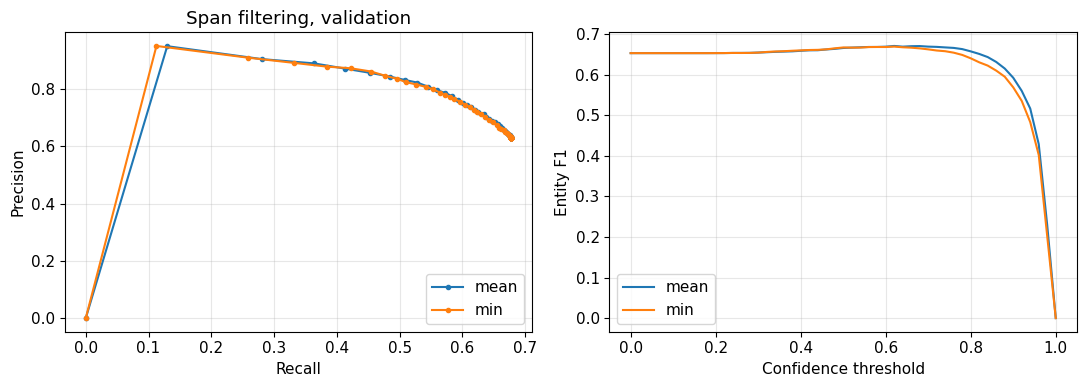

In [48]:
if '6.5' in BONUS_TASKS:
    def threshold_spans(tags_list, probs_list, threshold, aggregation='mean'):
        result = []
        for tags, probs in zip(tags_list, probs_list, strict=True):
            kept = []
            for a, b, typ in bio_to_spans(tags):
                confidence = float(np.mean(probs[a:b]) if aggregation == 'mean' else np.min(probs[a:b]))
                if confidence >= threshold:
                    kept.append((a, b, typ))
            result.append(spans_to_bio(kept, len(tags)))
        return result

    thresholds = np.linspace(0, 1, 51)
    threshold_results = {}
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for aggregation in ['mean', 'min']:
        rows = []
        for threshold in thresholds:
            pred = threshold_spans(val_pred, val_probs, float(threshold), aggregation)
            rows.append(dict(threshold=float(threshold), **entity_scores(val_gold, pred)))
        # При равном F1 выбираем меньший порог, сохраняющий больше спанов.
        best_row = max(rows, key=lambda row: (row['f1_micro'], -row['threshold']))
        assert all(rows[i+1]['recall'] <= rows[i]['recall'] + 1e-12 for i in range(len(rows)-1))
        threshold_results[aggregation] = dict(curve=rows, best=best_row,
            gain=best_row['f1_micro']-rows[0]['f1_micro'])
        axes[0].plot([r['recall'] for r in rows], [r['precision'] for r in rows], '.-', label=aggregation)
        axes[1].plot(thresholds, [r['f1_micro'] for r in rows], label=aggregation)
        print(aggregation, 'best:', best_row, 'gain:', threshold_results[aggregation]['gain'])
    axes[0].set(xlabel='Recall', ylabel='Precision', title='Span filtering, validation')
    axes[1].set(xlabel='Confidence threshold', ylabel='Entity F1')
    for ax in axes: ax.legend(); ax.grid(alpha=.3)
    fig.tight_layout(); fig.savefig(ARTIFACTS / 'precision_recall.png', dpi=150)
    plt.show()
    (ARTIFACTS / 'bonus_6_5.json').write_text(json.dumps(threshold_results, indent=2))


**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** Средняя уверенность может скрывать одно сомнительное слово длинного имени, минимум отбрасывает спан, как только хотя бы одно слово ненадежно. Порог подбирается только по validation, поэтому максимум F1 на этой кривой оптимистичен для будущих данных и не заменяет независимую оценку. Удаление готовых спанов может повысить precision ценой recall; создать новый правильный спан или исправить границу оно не может, поэтому recall не возрастает. При нулевом пороге исходный BIO канонизируется без изменения множества сущностей.


In [49]:
if '6.5' in BONUS_TASKS:
    display(Markdown(' '.join(
        f'**{aggregation}**: лучший порог **{r["best"]["threshold"]:.2f}**, '
        f'validation F1 **{r["best"]["f1_micro"]:.4f}**, '
        f'выигрыш к нулевому порогу **{r["gain"]:+.4f}**.'
        for aggregation, r in threshold_results.items())))

# Итоговый манифест после бонусов: metrics.json из шаблона остается на месте.
environment = dict(python=sys.version, platform=platform.platform(), device=DEVICE_NAME,
    torch=torch.__version__, transformers=transformers.__version__, datasets=datasets.__version__,
    cpu_threads=CPU_THREADS, fast_mode=FAST_MODE)
(ARTIFACTS / 'environment.json').write_text(json.dumps(environment, indent=2))
metrics.update(validation=val_final, dataset_revision=DATASET_REVISION,
    seed=SEED, hyperparameters=dict(epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, max_length=MAX_LENGTH,
        warmup_ratio=.1, weight_decay=.01), truncation=truncation_stats,
    bonus_tasks=sorted(BONUS_TASKS))
if '6.2' in BONUS_TASKS: metrics['alternative'] = alternative
if '6.3' in BONUS_TASKS: metrics['shift'] = shift_results
if '6.4' in BONUS_TASKS: metrics['quantization'] = quantization
if '6.5' in BONUS_TASKS: metrics['thresholds'] = threshold_results
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2))
print('Готово:', 'FAST_MODE' if FAST_MODE else 'FINAL', '| бонусы:', sorted(BONUS_TASKS))
print('Artifacts:', sorted(p.name for p in ARTIFACTS.iterdir() if p.is_file()))


Готово: FINAL | бонусы: ['6.2', '6.3', '6.4', '6.5']
Artifacts: ['bonus_6_2.json', 'bonus_6_3.json', 'bonus_6_4.json', 'bonus_6_5.json', 'data_lengths.png', 'dataset_stats.json', 'environment.json', 'error_categories.png', 'error_examples.json', 'f1_per_type.png', 'history_alternative.json', 'history_freeze.json', 'history_main.json', 'learning_curves.png', 'metrics.json', 'precision_recall.png', 'robustness.png', 'subset_manifest.json', 'validation.json']


**mean**: лучший порог **0.62**, validation F1 **0.6709**, выигрыш к нулевому порогу **+0.0177**. **min**: лучший порог **0.62**, validation F1 **0.6692**, выигрыш к нулевому порогу **+0.0161**.